In [4]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
accuracy_score,
classification_report,
confusion_matrix,
ConfusionMatrixDisplay,
roc_auc_score,
roc_curve
)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [6]:
from sklearn.ensemble import (
BaggingClassifier,
AdaBoostClassifier,
RandomForestClassifier,
GradientBoostingClassifier
)

In [7]:
from sklearn.pipeline import Pipeline

In [9]:
df = pd.read_csv("churn_dataset.csv")

print(df.head())


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [10]:
print(df.shape)

(7043, 21)


In [11]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [12]:
print(df.dtypes)

print("\nDataset information:")
df.info()

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str   

In [13]:
print(df.describe(include="all").T)

                   count unique               top  freq       mean        std  \
customerID          7043   7043        7590-VHVEG     1        NaN        NaN   
gender              7043      2              Male  3555        NaN        NaN   
SeniorCitizen     7043.0    NaN               NaN   NaN   0.162147   0.368612   
Partner             7043      2                No  3641        NaN        NaN   
Dependents          7043      2                No  4933        NaN        NaN   
tenure            7043.0    NaN               NaN   NaN  32.371149  24.559481   
PhoneService        7043      2               Yes  6361        NaN        NaN   
MultipleLines       7043      3                No  3390        NaN        NaN   
InternetService     7043      3       Fiber optic  3096        NaN        NaN   
OnlineSecurity      7043      3                No  3498        NaN        NaN   
OnlineBackup        7043      3                No  3088        NaN        NaN   
DeviceProtection    7043    

In [14]:
null_values = df.isnull().sum()

print(null_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [16]:
df["TotalCharges"] = pd.to_numeric(
df["TotalCharges"],
errors="coerce"

)
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [17]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [19]:
df = df.drop("customerID", axis=1)

In [20]:
df["Churn"] = df["Churn"].map({
"No": 0,
"Yes": 1
})

print("\nChurn value counts:")
print(df["Churn"].value_counts())


Churn value counts:
Churn
0    5174
1    1869
Name: count, dtype: int64


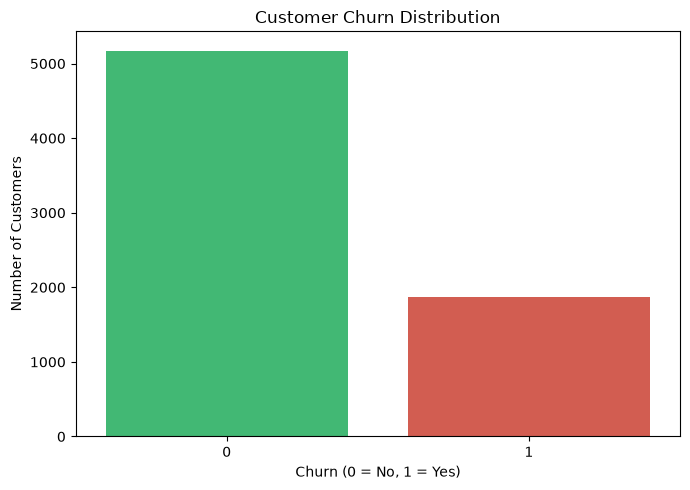

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
x="Churn",
data=df,
hue="Churn",
palette=["#2ecc71", "#e74c3c"],
legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [22]:
numerical_columns = [
"tenure",
"MonthlyCharges",
"TotalCharges"
]

print("\nNumerical attributes:")
print(numerical_columns)


Numerical attributes:
['tenure', 'MonthlyCharges', 'TotalCharges']


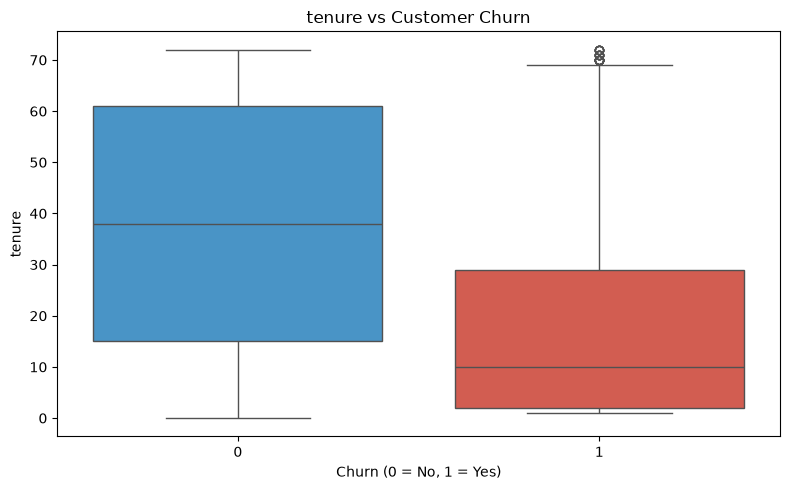

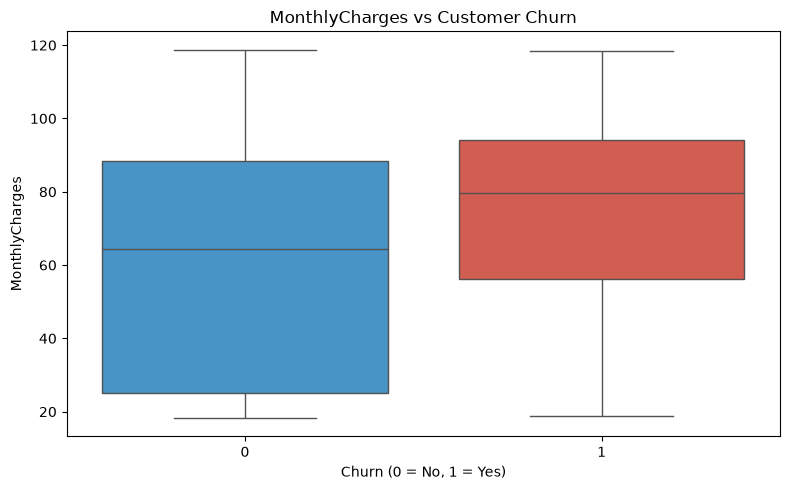

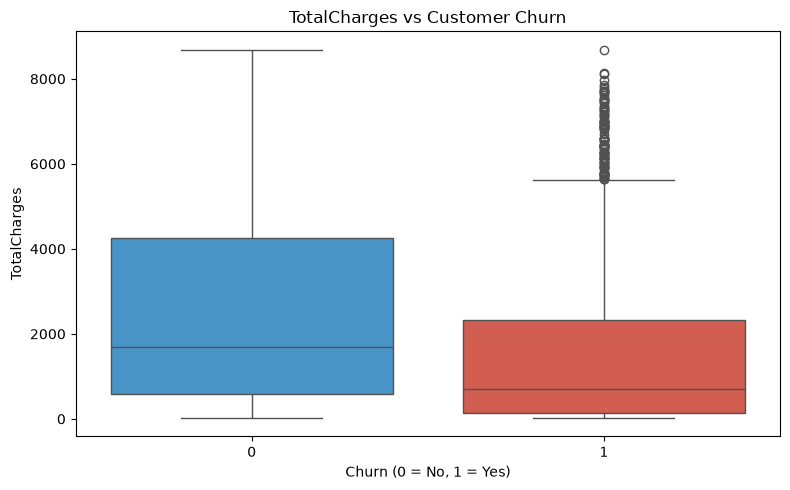

In [24]:
# ============================================================
# BOXPLOTS AGAINST CHURN
# ============================================================

for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        x="Churn",
        y=column,
        data=df,
        hue="Churn",
        palette=["#3498db", "#e74c3c"],
        legend=False
    )

    plt.title(f"{column} vs Customer Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()

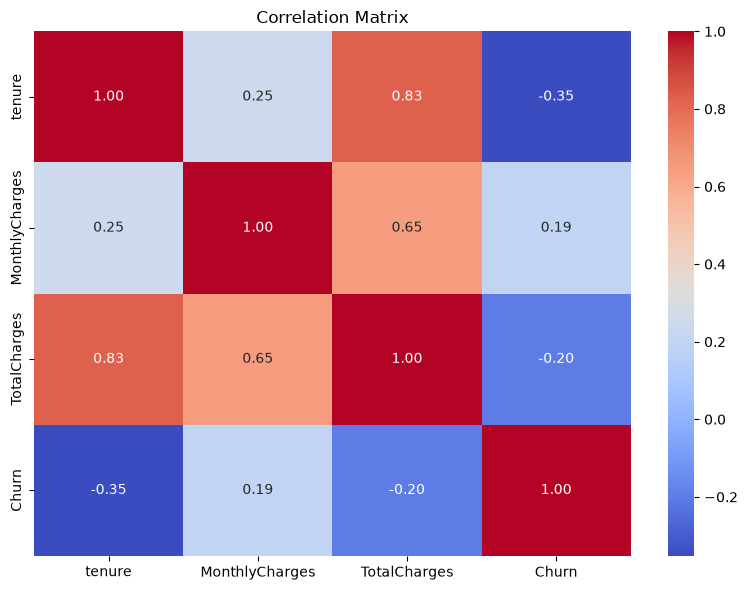

In [26]:
plt.figure(figsize=(8, 6))

correlation_matrix = df[numerical_columns + ["Churn"]].corr()

sns.heatmap(
correlation_matrix,
annot=True,
cmap="coolwarm",
fmt=".2f"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [27]:
categorical_columns = df.select_dtypes(
include=["object"]
).columns.tolist()

print("\nCategorical attributes:")
print(categorical_columns)


Categorical attributes:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


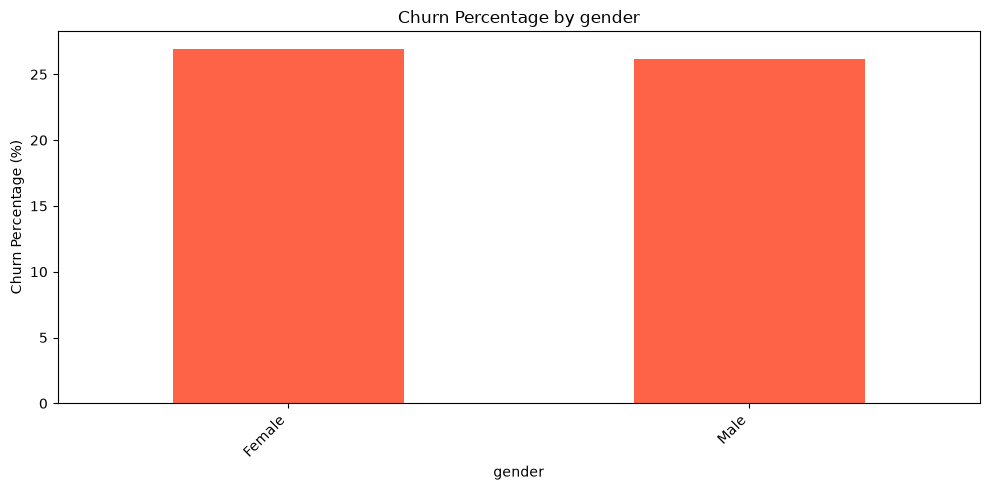

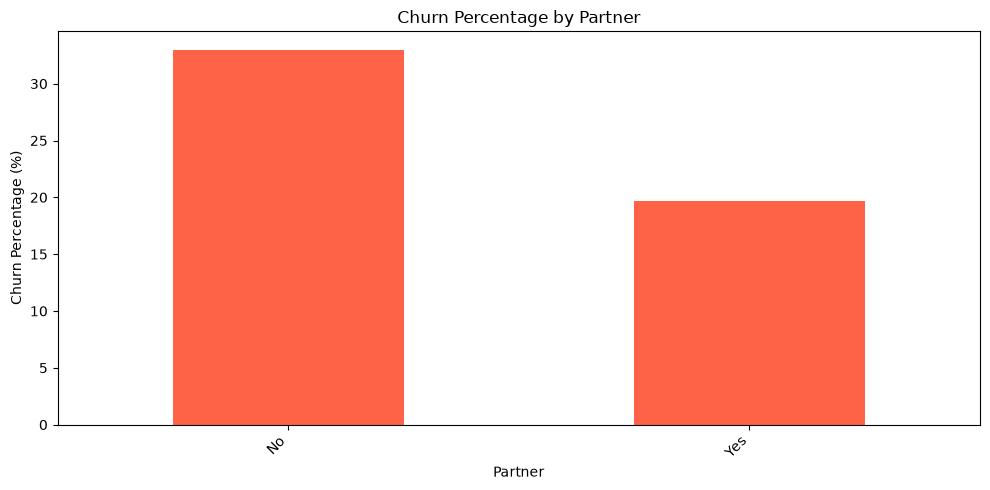

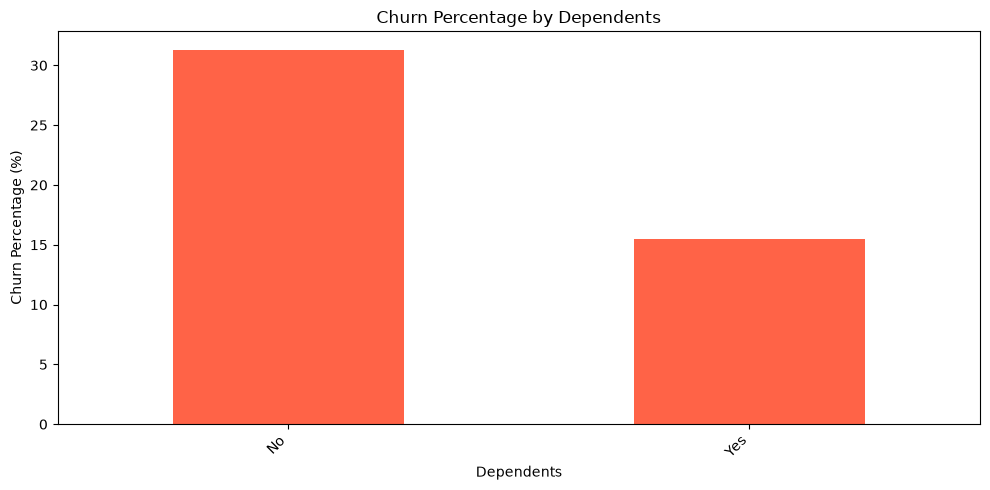

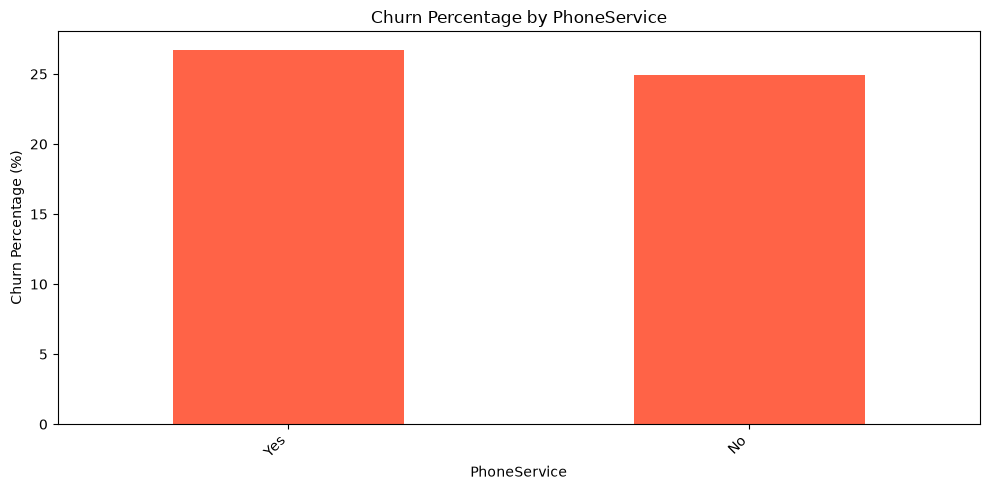

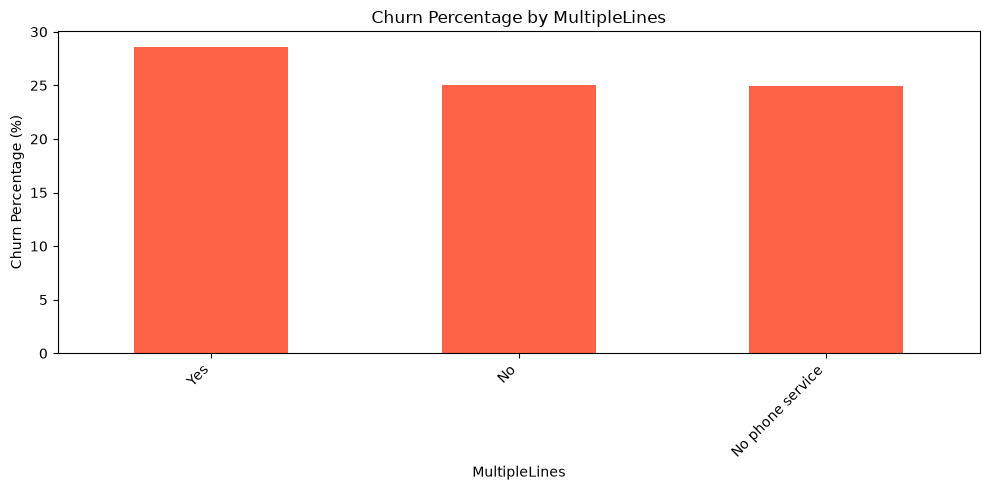

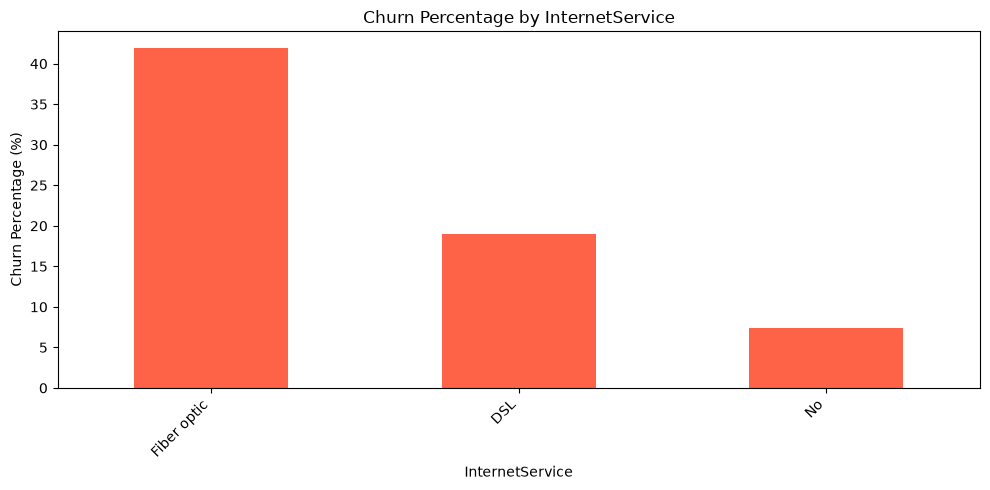

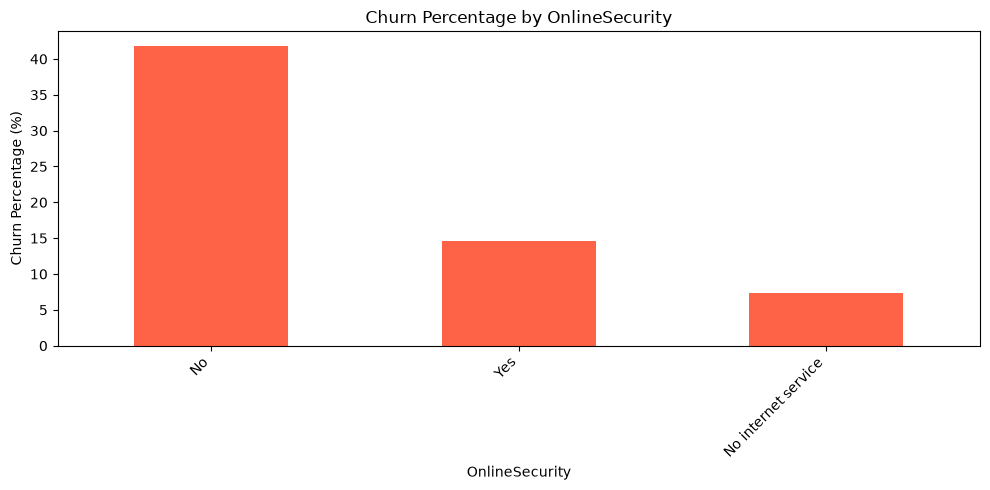

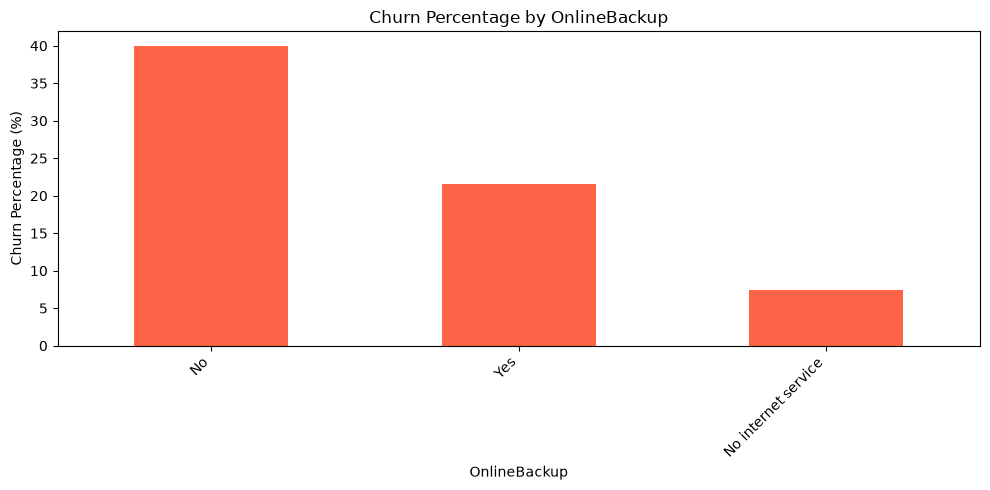

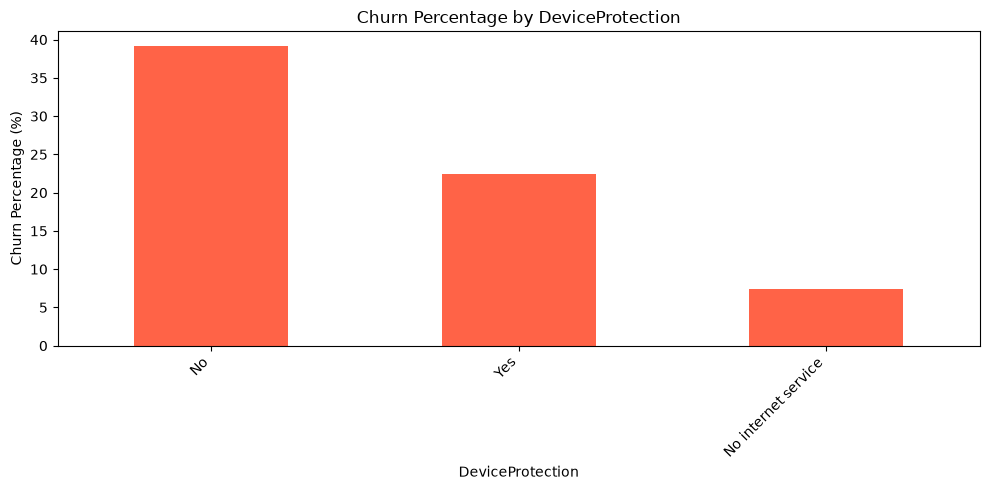

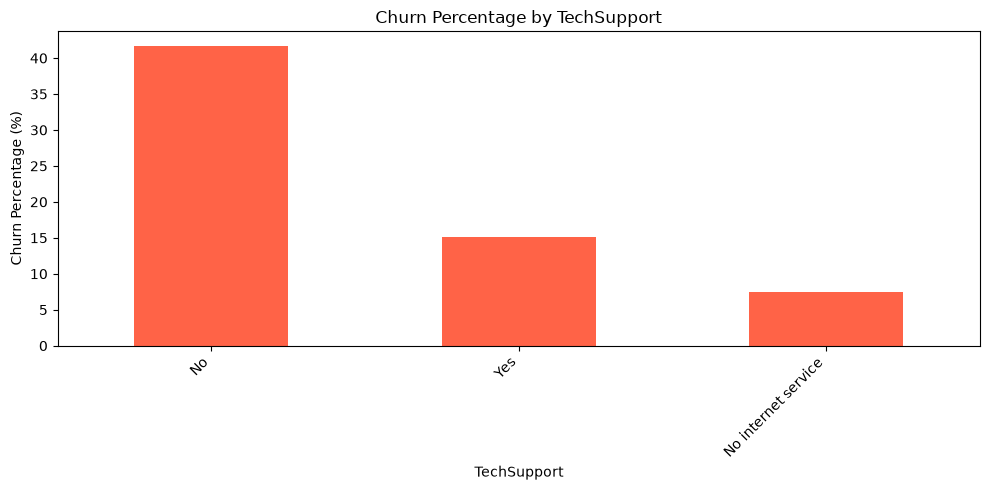

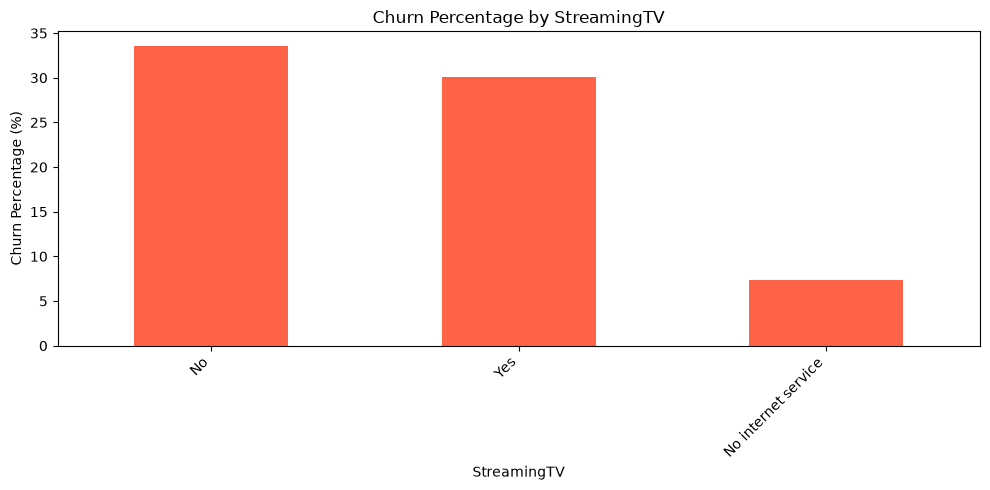

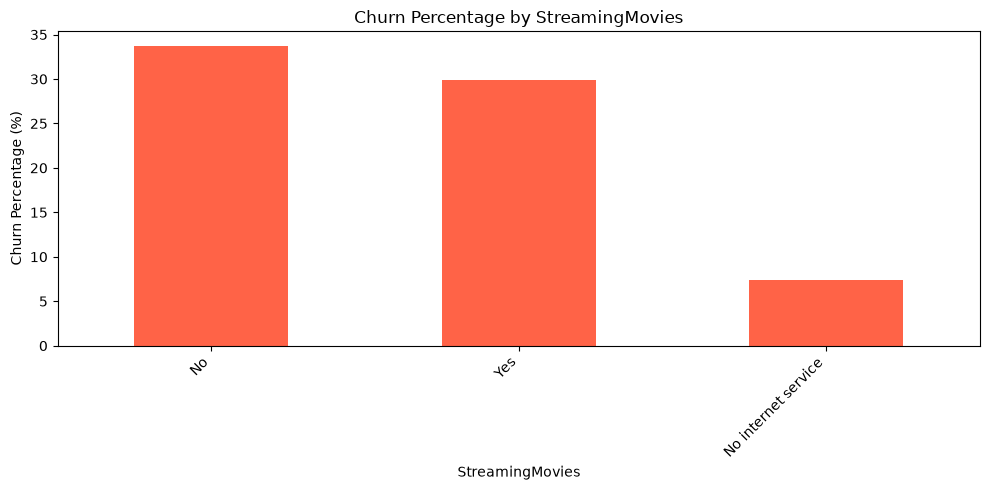

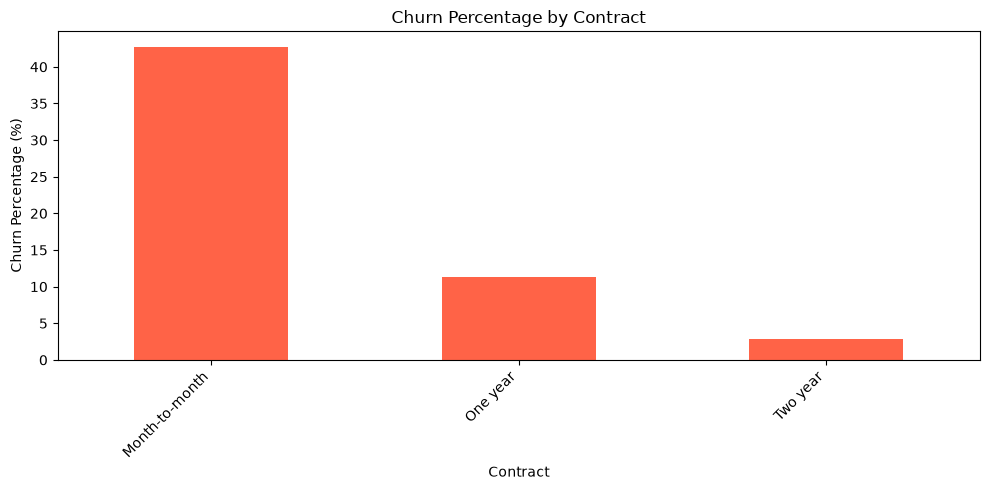

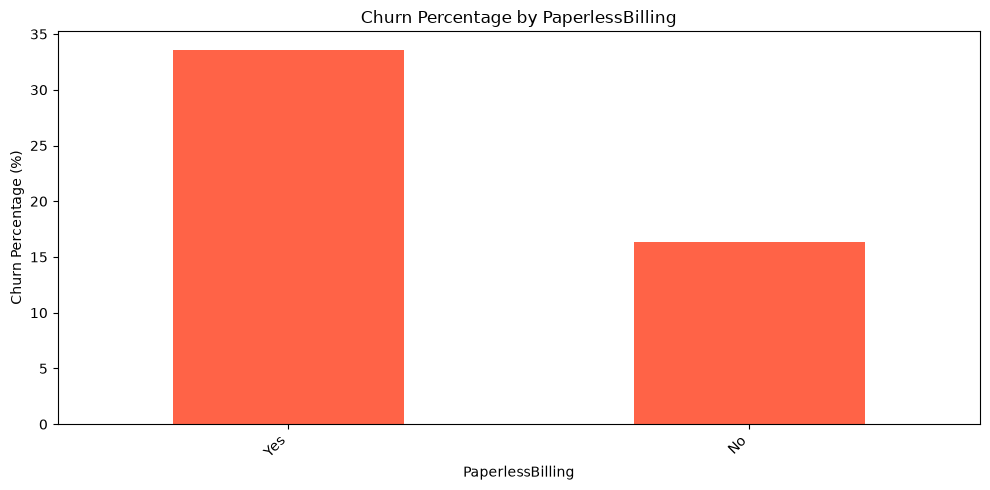

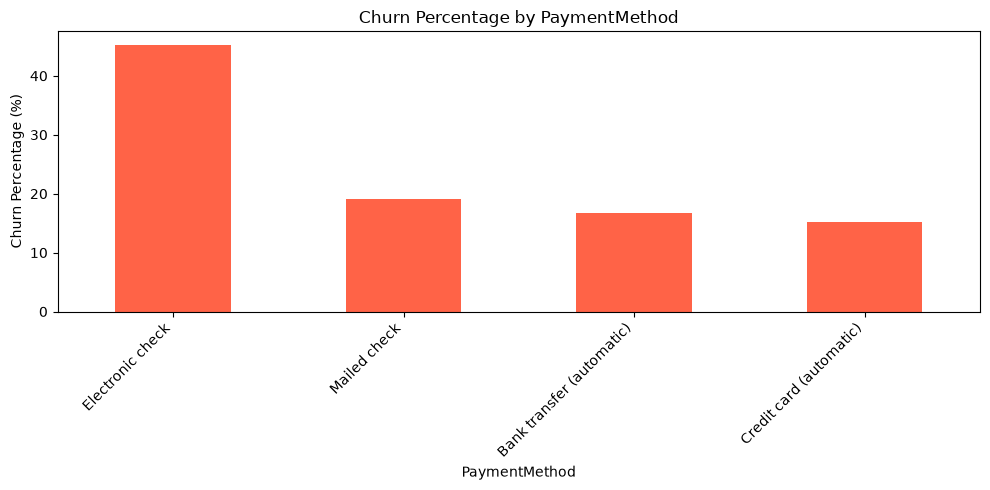

In [30]:
for column in categorical_columns:

    churn_percentage = (
        pd.crosstab(
            df[column],
            df["Churn"],
            normalize="index"
        ) * 100
    )

    if 1 in churn_percentage.columns:

        plt.figure(figsize=(10, 5))

        churn_percentage[1].sort_values(
            ascending=False
        ).plot(
            kind="bar",
            color="tomato"
        )

        plt.title(f"Churn Percentage by {column}")
        plt.xlabel(column)
        plt.ylabel("Churn Percentage (%)")

        plt.xticks(rotation=45, ha="right")

        plt.tight_layout()
        plt.show()

In [31]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (7043, 19)
Target shape: (7043,)


In [32]:
X = pd.get_dummies(
X,
drop_first=True
)

print("\nShape after one-hot encoding:")
print(X.shape)

print("\nEncoded feature names:")
print(X.columns.tolist())


Shape after one-hot encoding:
(7043, 30)

Encoded feature names:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42,
stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (5634, 30)
Testing data shape: (1409, 30)


In [48]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [35]:
models = {

"Logistic Regression":
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

"Decision Tree":
    DecisionTreeClassifier(
        random_state=42
    ),

"KNN":
    KNeighborsClassifier(
        n_neighbors=5
    ),

"Naive Bayes":
    GaussianNB(),

"SVM":
    SVC(
        probability=True,
        random_state=42
    )

}

In [55]:
print("Null values in X_train_scaled:")
print(np.isnan(X_train_scaled).sum())

Null values in X_train_scaled:
0


In [56]:
# Remove rows containing null values from X_train
valid_rows = X_train.notna().all(axis=1)

X_train = X_train.loc[valid_rows]
y_train = y_train.loc[valid_rows]

# Refit the scaler and update X_train_scaled
X_train_scaled = scaler.fit_transform(X_train)

print("Null values in X_train_scaled:",
      np.isnan(X_train_scaled).sum())

print("New X_train_scaled shape:",
      X_train_scaled.shape)

print("New y_train shape:",
      y_train.shape)

Null values in X_train_scaled: 0
New X_train_scaled shape: (5626, 30)
New y_train shape: (5626,)


In [57]:
print("Null values in X_train_scaled:")
print(np.isnan(X_train_scaled).sum())

Null values in X_train_scaled:
0



MODEL TRAINING AND EVALUATION

----------------------------------------------------------------------
Logistic Regression
----------------------------------------------------------------------

Accuracy: 0.8065
ROC-AUC: 0.8414

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1032
       Churn       0.66      0.57      0.61       374

    accuracy                           0.81      1406
   macro avg       0.75      0.73      0.74      1406
weighted avg       0.80      0.81      0.80      1406

Confusion Matrix:
[[922 110]
 [162 212]]


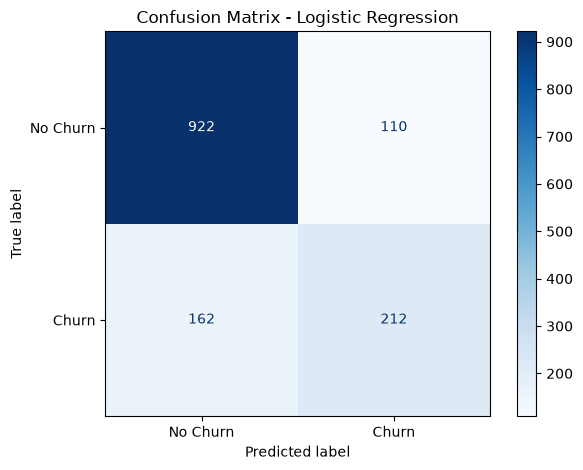


----------------------------------------------------------------------
Decision Tree
----------------------------------------------------------------------

Accuracy: 0.7326
ROC-AUC: 0.6503

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.83      0.82      1032
       Churn       0.50      0.48      0.49       374

    accuracy                           0.73      1406
   macro avg       0.66      0.65      0.65      1406
weighted avg       0.73      0.73      0.73      1406

Confusion Matrix:
[[852 180]
 [196 178]]


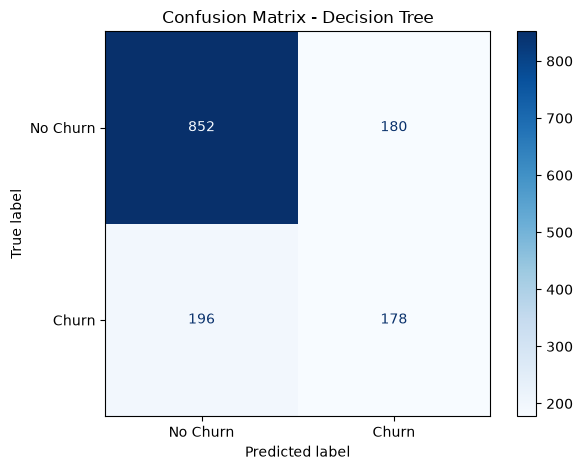


----------------------------------------------------------------------
KNN
----------------------------------------------------------------------

Accuracy: 0.7468
ROC-AUC: 0.7709

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.84      0.83      1032
       Churn       0.53      0.50      0.51       374

    accuracy                           0.75      1406
   macro avg       0.67      0.67      0.67      1406
weighted avg       0.74      0.75      0.74      1406

Confusion Matrix:
[[863 169]
 [187 187]]


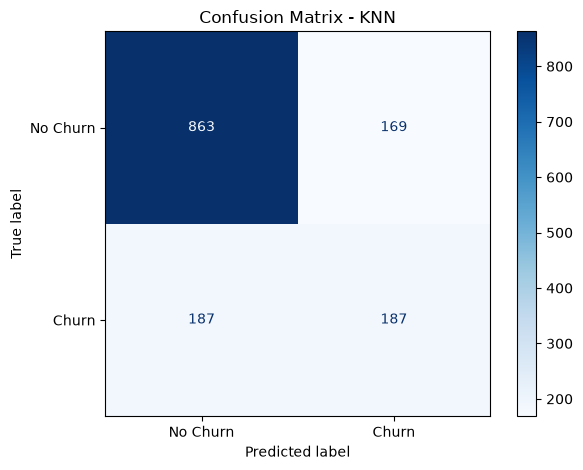


----------------------------------------------------------------------
Naive Bayes
----------------------------------------------------------------------

Accuracy: 0.6550
ROC-AUC: 0.8089

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.92      0.58      0.71      1032
       Churn       0.43      0.87      0.57       374

    accuracy                           0.66      1406
   macro avg       0.67      0.72      0.64      1406
weighted avg       0.79      0.66      0.67      1406

Confusion Matrix:
[[597 435]
 [ 50 324]]


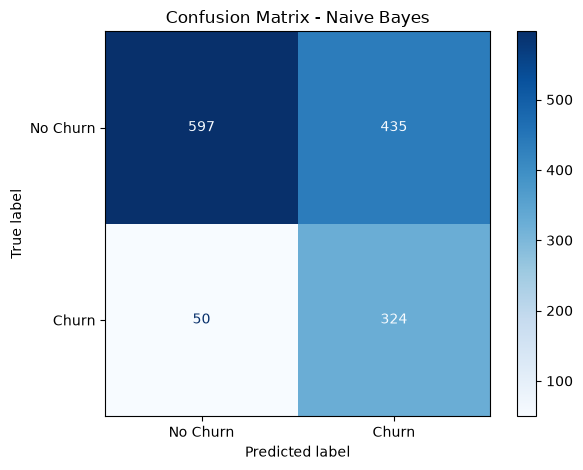


----------------------------------------------------------------------
SVM
----------------------------------------------------------------------

Accuracy: 0.7923
ROC-AUC: 0.7960

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1032
       Churn       0.64      0.49      0.56       374

    accuracy                           0.79      1406
   macro avg       0.74      0.70      0.71      1406
weighted avg       0.78      0.79      0.78      1406

Confusion Matrix:
[[931 101]
 [191 183]]


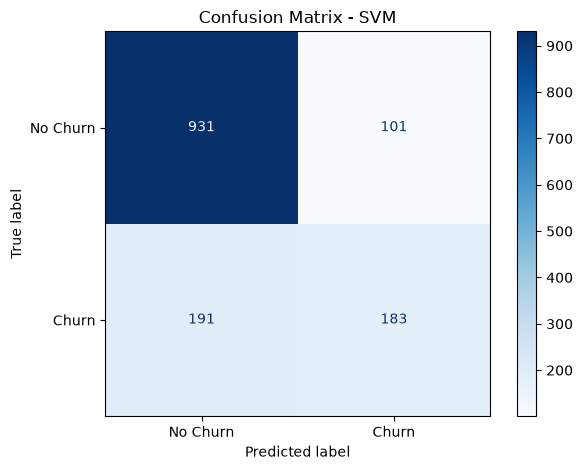

In [63]:
results = []

trained_models = {}

print("\n" + "=" * 70)
print("MODEL TRAINING AND EVALUATION")
print("=" * 70)

for name, model in models.items():

    print("\n" + "-" * 70)
    print(name)
    print("-" * 70)

    # Train model
    model.fit(
        X_train_scaled,
        y_train
    )

    # Predict
    y_pred = model.predict(
        X_test_scaled
    )

    # Predict probability
    y_probability = model.predict_proba(
        X_test_scaled
    )[:, 1]

    # Store trained model
    trained_models[name] = model

    # Accuracy
    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    # ROC-AUC
    roc_auc = roc_auc_score(
        y_test,
        y_probability
    )

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "ROC-AUC": roc_auc
    })

    print(
        f"\nAccuracy: {accuracy:.4f}"
    )

    print(
        f"ROC-AUC: {roc_auc:.4f}"
    )

    # Classification Report
    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "No Churn",
                "Churn"
            ]
        )
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred
    )

    print("Confusion Matrix:")
    print(cm)

    # Display Confusion Matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Churn",
            "Churn"
        ]
    )

    disp.plot(
        cmap="Blues"
    )

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.tight_layout()
    plt.show()

In [60]:
# Check null values in X_test_scaled

print("Null values in X_test_scaled:",
      np.isnan(X_test_scaled).sum())

Null values in X_test_scaled: 3


In [61]:
# Find rows in X_test that do not contain null values
valid_rows = X_test.notna().all(axis=1)

# Remove the same rows from X_test and y_test
X_test = X_test.loc[valid_rows]
y_test = y_test.loc[valid_rows]

# Update X_test_scaled
X_test_scaled = scaler.transform(X_test)

print("Null values in X_test_scaled:",
      np.isnan(X_test_scaled).sum())

print("New X_test_scaled shape:",
      X_test_scaled.shape)

print("New y_test shape:",
      y_test.shape)

Null values in X_test_scaled: 0
New X_test_scaled shape: (1406, 30)
New y_test shape: (1406,)


In [62]:
print("Null values in X_test:",
      X_test.isnull().sum().sum())

print("Null values in X_test_scaled:",
      np.isnan(X_test_scaled).sum())

print("Null values in y_test:",
      y_test.isnull().sum())

Null values in X_test: 0
Null values in X_test_scaled: 0
Null values in y_test: 0


In [64]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
by="Accuracy",
ascending=False
)

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

print(
results_df.to_string(
index=False
)
)


MODEL COMPARISON
              Model  Accuracy  ROC-AUC
Logistic Regression  0.806543 0.841443
                SVM  0.792319 0.795955
                KNN  0.746799 0.770911
      Decision Tree  0.732575 0.650251
        Naive Bayes  0.655050 0.808896


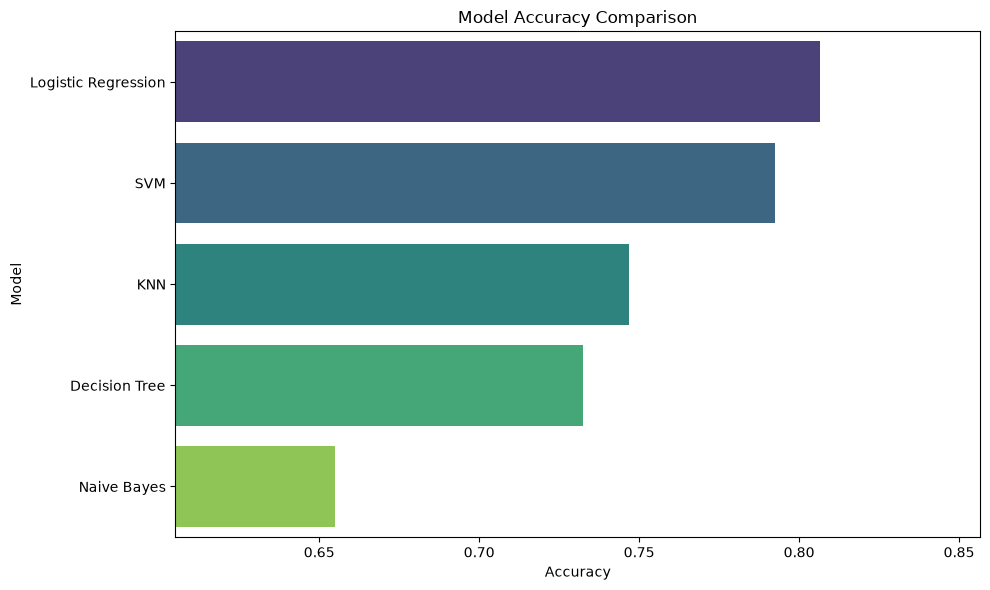

In [65]:
plt.figure(figsize=(10, 6))

sns.barplot(
data=results_df,
x="Accuracy",
y="Model",
hue="Model",
palette="viridis",
legend=False
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")

plt.xlim(
max(0, results_df["Accuracy"].min() - 0.05),
min(1, results_df["Accuracy"].max() + 0.05)
)

plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("5-FOLD CROSS VALIDATION")
print("=" * 70)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Std": scores.std()
    })

    print(
        f"{name}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )


# Convert results to DataFrame

cv_results_df = pd.DataFrame(
    cv_results
)

print("\nCross-validation results:")

print(
    cv_results_df.to_string(
        index=False
    )
)


5-FOLD CROSS VALIDATION


Logistic Regression: 0.8038 (+/- 0.0134)
Decision Tree: 0.7254 (+/- 0.0026)
KNN: 0.7624 (+/- 0.0109)
Naive Bayes: 0.6623 (+/- 0.0206)
SVM: 0.8039 (+/- 0.0138)

Cross-validation results:
              Model  Mean CV Accuracy      Std
Logistic Regression          0.803764 0.013351
      Decision Tree          0.725382 0.002578
                KNN          0.762350 0.010900
        Naive Bayes          0.662279 0.020596
                SVM          0.803942 0.013806


In [68]:
print("\n" + "=" * 70)
print("GRIDSEARCHCV - LOGISTIC REGRESSION")
print("=" * 70)

logistic_pipeline = Pipeline([
("scaler", StandardScaler()),
("model", LogisticRegression(
max_iter=2000,
random_state=42
))
])

logistic_parameters = {
"model__C": [
0.01,
0.1,
1,
10,
100
],

"model__solver": [
    "liblinear",
    "lbfgs"
]

}

grid_logistic = GridSearchCV(
logistic_pipeline,
logistic_parameters,
cv=5,
scoring="accuracy",
n_jobs=-1
)

grid_logistic.fit(
X_train,
y_train
)

print(
"Best Parameters:",
grid_logistic.best_params_
)

print(
"Best CV Accuracy:",
grid_logistic.best_score_
)


GRIDSEARCHCV - LOGISTIC REGRESSION
Best Parameters: {'model__C': 100, 'model__solver': 'liblinear'}
Best CV Accuracy: 0.8050082494572726


In [69]:
print("\n" + "=" * 70)
print("GRIDSEARCHCV - DECISION TREE")
print("=" * 70)

tree = DecisionTreeClassifier(
random_state=42
)

tree_parameters = {
"max_depth": [
None,
3,
5,
7,
10
],

"min_samples_split": [
    2,
    5,
    10
],

"criterion": [
    "gini",
    "entropy"
]

}

grid_tree = GridSearchCV(
tree,
tree_parameters,
cv=5,
scoring="accuracy",
n_jobs=-1
)

grid_tree.fit(
X_train,
y_train
)

print(
"Best Parameters:",
grid_tree.best_params_
)

print(
"Best CV Accuracy:",
grid_tree.best_score_
)


GRIDSEARCHCV - DECISION TREE
Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best CV Accuracy: 0.7872350503256366


In [70]:
print("\n" + "=" * 70)
print("GRIDSEARCHCV - KNN")
print("=" * 70)

knn_pipeline = Pipeline([
("scaler", StandardScaler()),
("model", KNeighborsClassifier())
])

knn_parameters = {
"model__n_neighbors": [
3,
5,
7,
9,
11,
15
],

"model__weights": [
    "uniform",
    "distance"
],

"model__metric": [
    "euclidean",
    "manhattan"
]

}

grid_knn = GridSearchCV(
knn_pipeline,
knn_parameters,
cv=5,
scoring="accuracy",
n_jobs=-1
)

grid_knn.fit(
X_train,
y_train
)

print(
"Best Parameters:",
grid_knn.best_params_
)

print(
"Best CV Accuracy:",
grid_knn.best_score_
)


GRIDSEARCHCV - KNN
Best Parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 15, 'model__weights': 'uniform'}
Best CV Accuracy: 0.7879456877836983


In [72]:
print("\n" + "=" * 70)
print("GRIDSEARCHCV - SVM")
print("=" * 70)

svm_pipeline = Pipeline([
("scaler", StandardScaler()),
("model", SVC(
probability=True,
random_state=42
))
])

svm_parameters = {
"model__C": [
0.1,
1,
10
],

"model__kernel": [
    "linear",
    "rbf"
],

"model__gamma": [
    "scale",
    "auto"
]

}

grid_svm = GridSearchCV(
svm_pipeline,
svm_parameters,
cv=5,
scoring="accuracy",
n_jobs=-1
)

grid_svm.fit(
X_train,
y_train
)

print(
"Best Parameters:",
grid_svm.best_params_
)

print(
"Best CV Accuracy:",
grid_svm.best_score_
)


GRIDSEARCHCV - SVM
Best Parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best CV Accuracy: 0.8039418985593054


In [73]:
print("\n" + "=" * 70)
print("ADABOOST CLASSIFIER")
print("=" * 70)

adaboost = AdaBoostClassifier(
n_estimators=100,
learning_rate=0.5,
random_state=42
)

adaboost.fit(
X_train,
y_train
)

ada_pred = adaboost.predict(
X_test
)

ada_probability = adaboost.predict_proba(
X_test
)[:, 1]

print(
"AdaBoost Accuracy:",
accuracy_score(
y_test,
ada_pred
)
)

print(
"AdaBoost ROC-AUC:",
roc_auc_score(
y_test,
ada_probability
)
)

print("\nAdaBoost Classification Report:")

print(
classification_report(
y_test,
ada_pred,
target_names=[
"No Churn",
"Churn"
]
)
)


ADABOOST CLASSIFIER
AdaBoost Accuracy: 0.7887624466571835
AdaBoost ROC-AUC: 0.8402069601625004

AdaBoost Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.91      0.86      1032
       Churn       0.65      0.45      0.53       374

    accuracy                           0.79      1406
   macro avg       0.73      0.68      0.70      1406
weighted avg       0.77      0.79      0.78      1406



In [74]:
print("\n" + "=" * 70)
print("RANDOM FOREST")
print("=" * 70)

random_forest = RandomForestClassifier(
n_estimators=200,
random_state=42,
n_jobs=-1
)

random_forest.fit(
X_train,
y_train
)

rf_pred = random_forest.predict(
X_test
)

rf_probability = random_forest.predict_proba(
X_test
)[:, 1]

print(
"Random Forest Accuracy:",
accuracy_score(
y_test,
rf_pred
)
)

print(
"Random Forest ROC-AUC:",
roc_auc_score(
y_test,
rf_probability
)
)

print("\nRandom Forest Classification Report:")

print(
classification_report(
y_test,
rf_pred,
target_names=[
"No Churn",
"Churn"
]
)
)


RANDOM FOREST
Random Forest Accuracy: 0.7887624466571835
Random Forest ROC-AUC: 0.8265011607179868

Random Forest Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1032
       Churn       0.63      0.51      0.56       374

    accuracy                           0.79      1406
   macro avg       0.73      0.70      0.71      1406
weighted avg       0.78      0.79      0.78      1406



In [75]:
feature_importance = pd.DataFrame({
"Feature": X.columns,
"Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
by="Importance",
ascending=False
)

print("\n" + "=" * 70)
print("TOP 15 IMPORTANT FEATURES")
print("=" * 70)

print(
feature_importance.head(15).to_string(
index=False
)
)


TOP 15 IMPORTANT FEATURES
                       Feature  Importance
                  TotalCharges    0.194882
                MonthlyCharges    0.169427
                        tenure    0.167024
   InternetService_Fiber optic    0.039056
PaymentMethod_Electronic check    0.038398
             Contract_Two year    0.031916
                   gender_Male    0.027812
            OnlineSecurity_Yes    0.026619
          PaperlessBilling_Yes    0.025215
                   Partner_Yes    0.024306
             Contract_One year    0.024158
               TechSupport_Yes    0.022715
              OnlineBackup_Yes    0.021945
             MultipleLines_Yes    0.020970
                 SeniorCitizen    0.020782


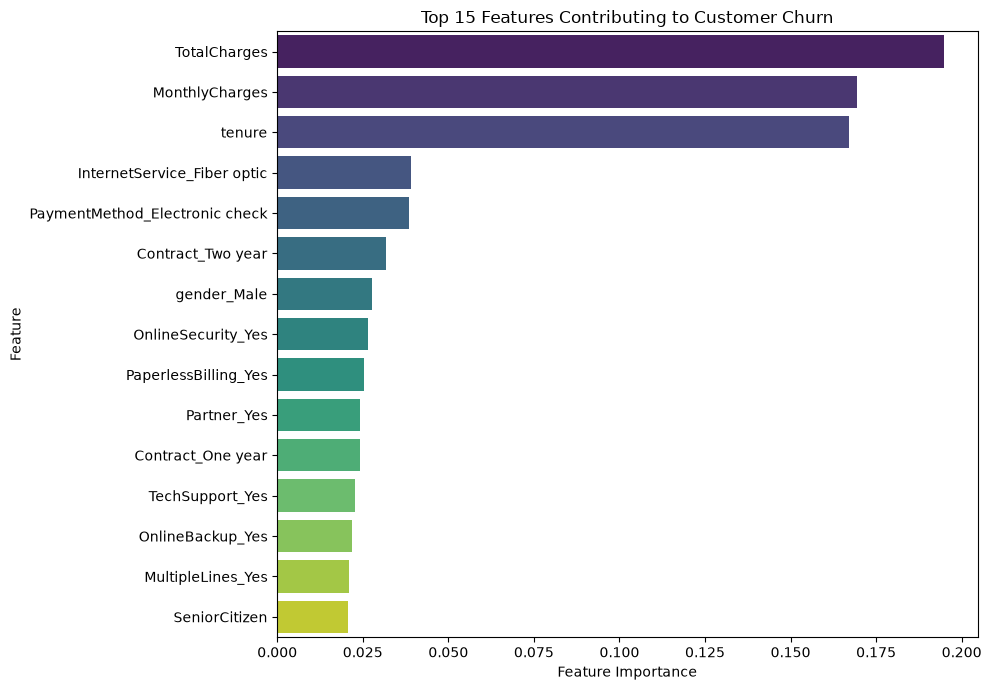

In [78]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
data=top_features,
x="Importance",
y="Feature",
hue="Feature",
palette="viridis",
legend=False
)

plt.title(
"Top 15 Features Contributing to Customer Churn"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()



final_model = random_forest

final_probability = final_model.predict_proba(
X_test
)[:, 1]

final_prediction = final_model.predict(
X_test
)

In [79]:
prediction_results = pd.DataFrame({
"Actual_Churn": y_test.values,
"Predicted_Churn": final_prediction,
"Churn_Probability": final_probability
})

In [80]:
prediction_results

,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.000
1,0,1,0.825
2,0,0,0.080
3,0,0,0.290
4,0,0,0.010
...,...,...,...
1401,0,0,0.065
1402,0,0,0.000
1403,0,0,0.040
1404,0,0,0.045


In [83]:
def classify_risk(probability):

    if probability < 0.30:
        return "Low Risk"

    elif probability < 0.70:
        return "Medium Risk"

    else:
        return "High Risk"


prediction_results["Risk_Level"] = (
    prediction_results["Churn_Probability"]
    .apply(classify_risk)
)


print("\n" + "=" * 70)
print("CUSTOMER CHURN PROBABILITY AND RISK")
print("=" * 70)


print(
    prediction_results.head(20).to_string(
        index=False
    )
)


CUSTOMER CHURN PROBABILITY AND RISK
 Actual_Churn  Predicted_Churn  Churn_Probability  Risk_Level
            0                0              0.000    Low Risk
            0                1              0.825   High Risk
            0                0              0.080    Low Risk
            0                0              0.290    Low Risk
            0                0              0.010    Low Risk
            0                0              0.340 Medium Risk
            0                0              0.355 Medium Risk
            0                0              0.075    Low Risk
            0                0              0.000    Low Risk
            1                0              0.455 Medium Risk
            0                0              0.140    Low Risk
            0                0              0.000    Low Risk
            0                0              0.240    Low Risk
            1                1              0.725   High Risk
            0                0   

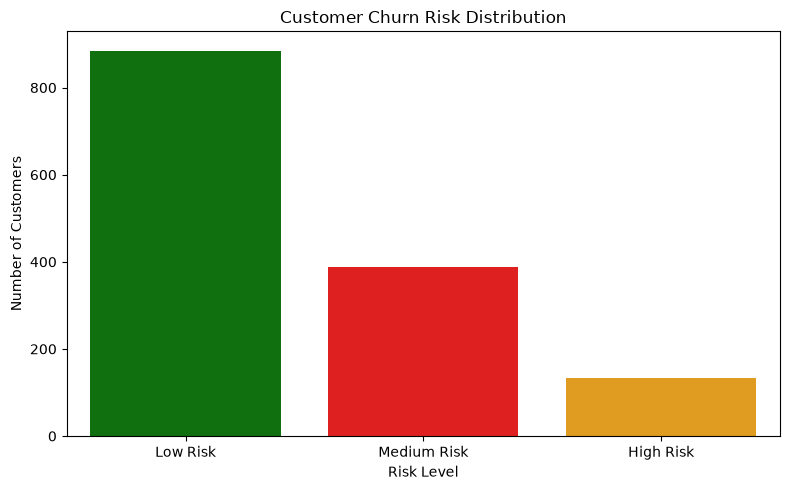

In [84]:
plt.figure(figsize=(8, 5))

sns.countplot(
x="Risk_Level",
data=prediction_results,
hue="Risk_Level",
order=[
"Low Risk",
"Medium Risk",
"High Risk"
],
palette=[
"green",
"orange",
"red"
],
legend=False
)

plt.title(
"Customer Churn Risk Distribution"
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [85]:
print("\n" + "=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print("\nBasic Models:")
print(
results_df.to_string(
index=False
)
)

print("\nCross Validation:")
print(
cv_results_df.to_string(
index=False
)
)

print("\nTop Important Features:")
print(
feature_importance.head(10).to_string(
index=False
)
)

print("\nProject execution completed successfully!")


FINAL PROJECT SUMMARY

Basic Models:
              Model  Accuracy  ROC-AUC
Logistic Regression  0.806543 0.841443
                SVM  0.792319 0.795955
                KNN  0.746799 0.770911
      Decision Tree  0.732575 0.650251
        Naive Bayes  0.655050 0.808896

Cross Validation:
              Model  Mean CV Accuracy      Std
Logistic Regression          0.803764 0.013351
      Decision Tree          0.725382 0.002578
                KNN          0.762350 0.010900
        Naive Bayes          0.662279 0.020596
                SVM          0.803942 0.013806

Top Important Features:
                       Feature  Importance
                  TotalCharges    0.194882
                MonthlyCharges    0.169427
                        tenure    0.167024
   InternetService_Fiber optic    0.039056
PaymentMethod_Electronic check    0.038398
             Contract_Two year    0.031916
                   gender_Male    0.027812
            OnlineSecurity_Yes    0.026619
          Paper